# FlashAttention-3 from scratch: asynchrony, overlap and FP8

*Notebook 3 of 6. Prerequisite: notebook 2 (FA-2 loop structure). Hardware-heavy: we emulate what we cannot run.*

**TL;DR.** FlashAttention-2 *reportedly* reaches about 35% of an H100's peak FP16 throughput (Shah et al., 2024, [arXiv:2407.08608](https://arxiv.org/abs/2407.08608)), because the H100's matmul units are fast enough that the *non-matmul* work, mainly the softmax `exp`, becomes a visible fraction of the runtime and nothing overlaps it. FlashAttention-3 *reports* 1.5-2.0x speedup over FA-2 in FP16 (up to ~740 TFLOP/s, about 75% of peak) and close to 1.2 PFLOP/s in FP8, with 2.6x lower numerical error than a baseline FP8 attention. It does this with three ideas: (1) asynchronous data movement and matmul with specialised producer/consumer warps, (2) overlapping softmax of one warpgroup with matmuls of another ("ping-pong") and inside one warpgroup (software pipelining), and (3) FP8 with block quantisation and incoherent processing.

**What we do and do not show.** We have no H100. The speed figures above are *reported*, not measured here. What we can do: (a) show with arithmetic why softmax matters on Hopper, (b) build a small discrete-event simulator of the TMA / tensor-core / special-function units and measure how much each scheduling idea helps *in that model*, (c) implement the software-pipelined loop order and prove it exact, and (d) run a real numerical experiment on FP8 error with and without incoherent processing, using PyTorch's `float8_e4m3fn` dtype on CPU.

**Contents**
1. Why softmax is a bottleneck on Hopper
2. Producer-consumer warps and asynchronous copies
3. Ping-pong scheduling between warpgroups
4. Pipelining inside a warpgroup (exact, and its register cost)
5. FP8 attention: error, block quantisation, incoherent processing
6. What did not help, and what it costs
7. Closing thoughts

In [1]:
import math, heapq, numpy as np, torch, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from fa_kit import *
torch.manual_seed(0); HEAD = {}; print('device:', DEVICE)

device: cpu


## 1. Why softmax is a bottleneck on Hopper

**A tiny example.** For one $B_r\times B_c$ score tile the two matmuls cost $4B_rB_cd$ FLOPs and the softmax needs $B_rB_c$ exponentials. A Hopper H100 SXM is *reported* to deliver about 989 TFLOP/s of dense FP16 matmul but only about 3.9 TFLOP/s of special-function (`exp`) throughput. For head dimension $d=128$:

$$t_{\text{matmul}}=\frac{4d}{989\times10^{12}}=0.52\ \text{ps per score},\qquad t_{\exp}=\frac{1}{3.9\times10^{12}}=0.26\ \text{ps per score}.$$

So `exp` alone takes about half as long as both matmuls. If they run one after the other, the tensor cores idle for a third of the time.

    d | matmul ps/score | exp ps/score | exp/matmul | tensor-core util if serial
   64 |           0.259 |        0.256 |       0.99 |    50%
  128 |           0.518 |        0.256 |       0.50 |    67%
  256 |           1.035 |        0.256 |       0.25 |    80%


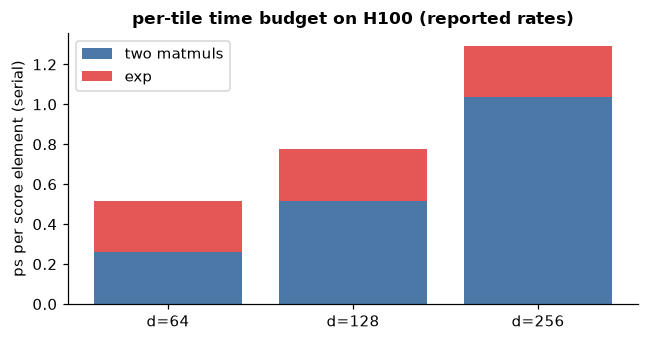

<sub>**Figure.** The red segment is the exp that the tensor cores must wait for if nothing overlaps. It shrinks relative to matmul as d grows (matmul cost is proportional to d, exp cost is not), so small head dimensions are hit hardest: at d=64 the exp takes as long as both matmuls together.</sub>

In [2]:
TC_FLOPS, SFU_OPS = 989e12, 3.9e12          # reported H100 SXM figures (dense fp16 tensor core, exp throughput)
print(f"{'d':>5} | matmul ps/score | exp ps/score | exp/matmul | tensor-core util if serial")
rows = []
for d in (64, 128, 256):
    tm, te = 4*d/TC_FLOPS*1e12, 1/SFU_OPS*1e12
    rows.append((d, tm, te)); print(f"{d:>5} | {tm:>15.3f} | {te:>12.3f} | {te/tm:>10.2f} | {tm/(tm+te)*100:>5.0f}%")
check("exp throughput is a first-order cost at d=128 (exp/matmul > 0.4)", rows[1][2]/rows[1][1] > 0.4)
fig, ax = plt.subplots(figsize=(6, 3.2)); x = np.arange(3)
ax.bar(x, [r[1] for r in rows], color=COL["q"], label="two matmuls"); ax.bar(x, [r[2] for r in rows], bottom=[r[1] for r in rows], color=COL["o"], label="exp")
ax.set_xticks(x); ax.set_xticklabels([f"d={r[0]}" for r in rows]); ax.set_ylabel("ps per score element (serial)"); ax.legend(); ax.set_title("per-tile time budget on H100 (reported rates)")
plt.tight_layout(); plt.show()
caption("The red segment is the exp that the tensor cores must wait for if nothing overlaps. It shrinks relative to matmul as d grows (matmul cost is proportional to d, exp cost is not), so small head dimensions are hit hardest: at d=64 the exp takes as long as both matmuls together.")

Hardware features that make overlap possible (all *reported* in the FA-3 paper, not tested here): the **Tensor Memory Accelerator (TMA)** copies tiles between HBM and shared memory asynchronously, without using registers or issue slots; **WGMMA** (warpgroup matrix multiply-accumulate) launches a matmul asynchronously from a group of 4 warps; and warps can be **specialised** into *producers* (issue TMA loads) and *consumers* (issue WGMMA and compute softmax), with registers re-allocated to the consumers. The rest of this notebook uses a simple model of those units.

**Our simulator.** Three exclusive resources, TMA (copies), TC (tensor cores) and SFU (exp and other scalar work), serve tasks in units where one GEMM tile takes 1.0. The per-iteration tasks for one warpgroup are `ld` (K/V tile copy, duration $L=0.5$), `g0` ($S=QK^\top$, 1.0), `sm` (softmax, duration from section 1: $b=989/(2\cdot3.9\,d)$, 0.99 at $d=128$) and `g1` ($O\mathrel{+}=PV$, 1.0). TC tasks can be *asynchronous* (the warpgroup moves on after issuing them) or *synchronous* (it waits); softmax is always synchronous because the warpgroup computes it itself.

In [3]:
def simulate(d, iters=24, wgs=1, sync_tc=False, async_load=True, pipelined=False, tc_order=None, L=0.5, stages=2):
    """Discrete-event model of one SM running `wgs` warpgroups, each doing `iters` attention iterations.
    Returns (makespan, tc_utilisation, events[(wg, task, resource, start, end)])."""
    a = c = 1.0; b = TC_FLOPS / (2 * d * SFU_OPS)
    dur = {"g0": a, "sm": b, "g1": c}
    prog = []
    for w in range(wgs):
        ops = []
        if not pipelined:
            for t in range(iters):
                if not async_load: ops.append((w, "ld", t))                          # blocking copy inside the warpgroup
                ops += [(w, "g0", t), (w, "sm", t), (w, "g1", t)]
        else:
            ops = [(w, "g0", 0)]
            for t in range(iters):
                if t + 1 < iters: ops.append((w, "g0", t + 1))
                ops += [(w, "sm", t), (w, "g1", t)]
        prog.append(ops)
    ptr = [0] * wgs; wg_t = [0.0] * wgs; fin = {}; free = {"TMA": 0.0, "TC": 0.0, "SFU": 0.0}; events = []; ld_fin = {}
    tc_seq = None
    if tc_order == "rr":                      # barrier-enforced round-robin of tensor-core ops across warpgroups
        per = [[o for o in p if o[1] in ("g0", "g1")] for p in prog]; tc_seq = []
        for k in range(max(len(p) for p in per)):
            for w in range(wgs):
                if k < len(per[w]): tc_seq.append(per[w][k])
    tc_next = 0
    def load_done(w, t):
        if (w, t) not in ld_fin:
            ready = fin.get((w, "g1", t - stages), 0.0) if t >= stages else 0.0       # SMEM buffer reuse
            s = max(free["TMA"], ready); free["TMA"] = s + L; ld_fin[(w, t)] = s + L; events.append((w, f"ld{t}", "TMA", s, s + L))
        return ld_fin[(w, t)]
    def candidate(w):
        op = prog[w][ptr[w]]; _, kind, t = op
        if kind == "ld":
            return max(wg_t[w], free["TMA"]), op
        if kind == "g0": dep = load_done(w, t) if async_load else ld_fin.get((w, t), 0.0)
        elif kind == "sm": dep = fin[(w, "g0", t)]
        else:
            dep = max(fin[(w, "sm", t)], load_done(w, t) if async_load else 0.0)
        res = "SFU" if kind == "sm" else "TC"
        return max(wg_t[w], dep, free[res]), op
    done = 0; total = sum(len(p) for p in prog)
    while done < total:
        best = None
        for w in range(wgs):
            if ptr[w] >= len(prog[w]): continue
            op = prog[w][ptr[w]]
            if tc_seq is not None and op[1] in ("g0", "g1") and tc_seq[tc_next] != op: continue
            s, _ = candidate(w)
            if best is None or s < best[0]: best = (s, w)
        assert best is not None, "deadlock"
        s, w = best; _, kind, t = prog[w][ptr[w]]
        if kind == "ld":
            e = s + L; free["TMA"] = e; wg_t[w] = e; ld_fin[(w, t)] = e; events.append((w, f"ld{t}", "TMA", s, e))
        else:
            e = s + dur[kind]; res = "SFU" if kind == "sm" else "TC"; free[res] = e; fin[(w, kind, t)] = e; events.append((w, f"{kind}{t}", res, s, e))
            if kind == "sm" or sync_tc: wg_t[w] = e
            # else: async issue, the warpgroup proceeds immediately (wg_t unchanged)
            if kind in ("g0", "g1") and tc_seq is not None: tc_next += 1
        ptr[w] += 1; done += 1
    mk = max(e[4] for e in events); tc_busy = sum(e[4] - e[3] for e in events if e[2] == "TC")
    return mk, tc_busy / mk, events

# one-warpgroup sanity: serial FA-2 style must cost L + a + b + c per iteration
mk, u, _ = simulate(128, iters=10, wgs=1, sync_tc=True, async_load=False)
b128 = TC_FLOPS / (2 * 128 * SFU_OPS); print(f"serial model: makespan/iter = {mk/10:.3f}  expected L+a+b+c = {0.5 + 2 + b128:.3f}")
check("simulator reproduces the serial per-iteration cost", abs(mk / 10 - (0.5 + 2 + b128)) < 1e-6)

serial model: makespan/iter = 3.491  expected L+a+b+c = 3.491


True

We validated the simulator against the one case with a closed form (the fully serial schedule) before using it for anything else. Now the first design change.

## 2. Producer-consumer warps and asynchronous copies

**A tiny example.** Serially, an iteration costs $L+a+b+c$: load a K/V tile, then compute on it. With a dedicated producer warp issuing TMA copies into a 2-slot shared-memory ring buffer, tile $t+1$ is loaded while tile $t$ is being computed, so the load time disappears from the critical path as long as $L\le a+b+c$.

**General definition.** A producer runs ahead of the consumer by up to `stages` tiles, limited by buffer slots: it may start loading tile $t$ only once the consumer has finished with tile $t-\text{stages}$.

**How it is implemented.** In our simulator, `async_load=True` moves `ld` onto the TMA resource with exactly that buffer-reuse rule.

   d | A makespan  TC util | B makespan  TC util | B speedup
  64 |      143.4      45% |      127.9      50% | 1.12x
 128 |      111.7      57% |       96.2      67% | 1.16x
 256 |       95.8      67% |       80.3      80% | 1.19x


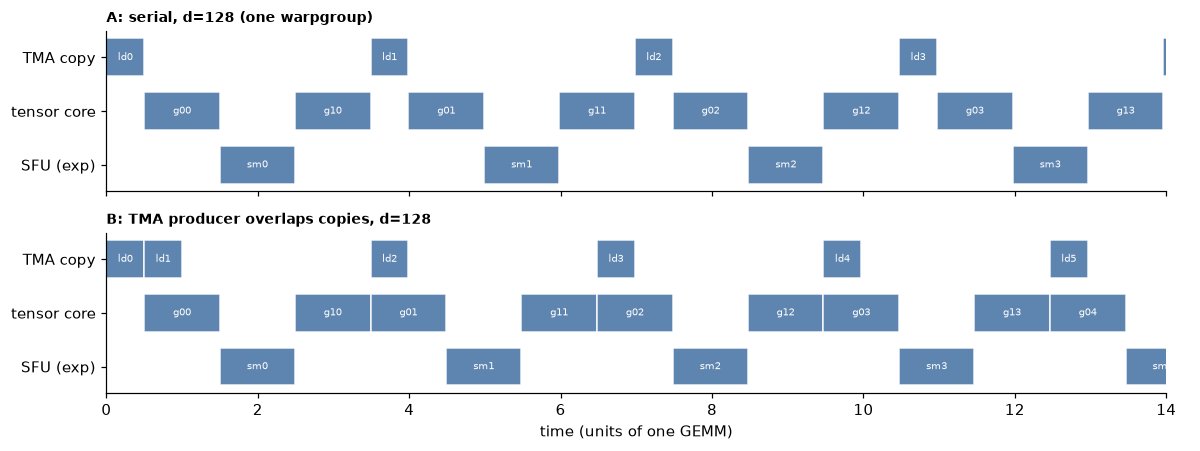

<sub>**Figure.** Each bar is one task; numbers are the loop iteration. In A the TMA lane is only used before each compute step, and in B it runs ahead (blue bars on the TMA lane overlap earlier compute). Notice what B does not fix: the tensor-core lane still has gaps equal to the softmax duration, because one warpgroup cannot start its next matmul until it has finished the softmax.</sub>

In [4]:
res = {}
for d in (64, 128, 256):
    for name, kw in (("A  serial (FA-2 style)", dict(wgs=1, sync_tc=True, async_load=False)),
                     ("B  + producer/TMA overlap", dict(wgs=1, sync_tc=True, async_load=True))):
        mk, u, ev = simulate(d, iters=32, **kw); res[(d, name[0])] = (mk, u, ev)
print(f"{'d':>4} | {'A makespan':>10} {'TC util':>8} | {'B makespan':>10} {'TC util':>8} | B speedup")
for d in (64, 128, 256):
    a_, b_ = res[(d, "A")], res[(d, "B")]; print(f"{d:>4} | {a_[0]:>10.1f} {a_[1]*100:>7.0f}% | {b_[0]:>10.1f} {b_[1]*100:>7.0f}% | {a_[0]/b_[0]:.2f}x")
check("async loads never slow the model down", all(res[(d, 'B')][0] <= res[(d, 'A')][0] for d in (64, 128, 256)))

def gantt(ax, ev, t0=0, t1=14, title=""):
    rows = {"TMA": 2, "TC": 1, "SFU": 0}; cols = {0: COL["q"], 1: COL["o"]}
    for w, nm, r, s, e in ev:
        if e < t0 or s > t1: continue
        ax.barh(rows[r], e - s, left=s, height=.7, color=cols[w], edgecolor="white", alpha=.9 if nm[0] in "gsl" else .5)
        ax.text((s + e) / 2, rows[r], nm, ha="center", va="center", fontsize=6.5, color="white")
    ax.set_yticks([0, 1, 2]); ax.set_yticklabels(["SFU (exp)", "tensor core", "TMA copy"]); ax.set_xlim(t0, t1); ax.set_title(title, fontsize=9, loc="left")
fig, axs = plt.subplots(2, 1, figsize=(11, 4.2), sharex=True)
gantt(axs[0], res[(128, "A")][2], title="A: serial, d=128 (one warpgroup)"); gantt(axs[1], res[(128, "B")][2], title="B: TMA producer overlaps copies, d=128"); axs[1].set_xlabel("time (units of one GEMM)")
plt.tight_layout(); plt.show()
caption("Each bar is one task; numbers are the loop iteration. In A the TMA lane is only used before each compute step, and in B it runs ahead (blue bars on the TMA lane overlap earlier compute). Notice what B does not fix: the tensor-core lane still has gaps equal to the softmax duration, because one warpgroup cannot start its next matmul until it has finished the softmax.")
HEAD["A"], HEAD["B"] = res[(128, "A")][:2], res[(128, "B")][:2]

The copy latency is hidden, but the model also shows its limit: the gaps on the tensor-core lane are the softmax itself, so something else must run on the tensor cores while one warpgroup is busy with `exp`.

## 3. Ping-pong scheduling between warpgroups

**A tiny example.** Give the SM *two* warpgroups, each working on a different Q tile. When warpgroup 0 is in its softmax (SFU busy, tensor core idle), warpgroup 1 can run its matmuls, and vice versa. If the two happen to line up badly the matmuls collide; FA-3 therefore uses named barriers to force them to alternate, calling this **ping-pong** scheduling.

**General definition.** Let the tensor-core ops of the two warpgroups be forced into a strict alternation $\text{WG0},\text{WG1},\text{WG0},\dots$ (`tc_order="rr"` in our simulator). Without the barrier, whichever warpgroup becomes ready first takes the unit.

   d |  B (1 WG) |         C |         D | TC util B / C / D
  64 |     3.997 |     2.038 |     2.989 | 50% / 98% / 67%
 128 |     3.006 |     2.255 |     2.008 | 67% / 89% / 100%
 256 |     2.511 |     2.132 |     2.008 | 80% / 94% / 100%


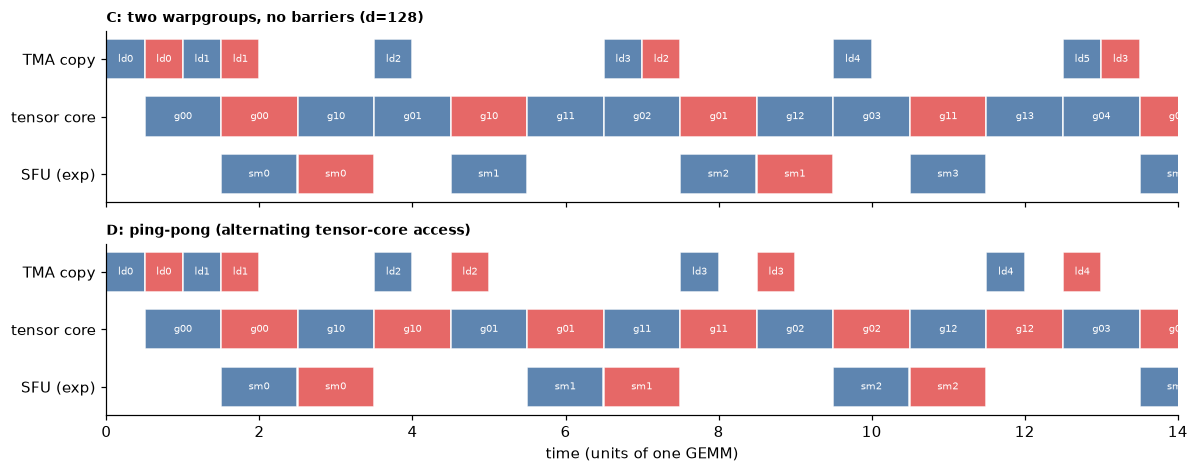

<sub>**Figure.** Blue = warpgroup 0, red = warpgroup 1. In D the tensor-core lane alternates blue/red and the SFU lane is busy whenever a warpgroup is not on the tensor core. Notice that the tensor core still has small gaps at d=128: softmax (0.99) is as long as one GEMM, so two warpgroups hide it only if the exp of one fits inside the matmuls of the other.</sub>

In [5]:
cfg = {"C  2 WGs, uncoordinated": dict(wgs=2, sync_tc=False, tc_order=None),
       "D  2 WGs, ping-pong barriers": dict(wgs=2, sync_tc=False, tc_order="rr")}
out = {}
print(f"{'d':>4} | {'B (1 WG)':>9} | {'C':>9} | {'D':>9} | TC util B / C / D")
for d in (64, 128, 256):
    row = [simulate(d, iters=32, wgs=1, sync_tc=True, async_load=True)]
    for nm, kw in cfg.items(): row.append(simulate(d, iters=32, **kw))
    out[d] = row
    # per-iteration work is 2x for two WGs, so compare time per (WG-iteration)
    per = [row[0][0] / 32, row[1][0] / 64, row[2][0] / 64]
    print(f"{d:>4} | {per[0]:>9.3f} | {per[1]:>9.3f} | {per[2]:>9.3f} | {row[0][1]*100:.0f}% / {row[1][1]*100:.0f}% / {row[2][1]*100:.0f}%")
HEAD["C128"], HEAD["D128"] = out[128][1][:2], out[128][2][:2]
check("two warpgroups beat one in the model at d=128", out[128][1][0] / 64 < out[128][0][0] / 32)
check("ping-pong is at least as good as uncoordinated at d=128", out[128][2][0] <= out[128][1][0] + 1e-9)
fig, axs = plt.subplots(2, 1, figsize=(11, 4.4), sharex=True)
gantt(axs[0], out[128][1][2], title="C: two warpgroups, no barriers (d=128)"); gantt(axs[1], out[128][2][2], title="D: ping-pong (alternating tensor-core access)"); axs[1].set_xlabel("time (units of one GEMM)")
plt.tight_layout(); plt.show()
caption("Blue = warpgroup 0, red = warpgroup 1. In D the tensor-core lane alternates blue/red and the SFU lane is busy whenever a warpgroup is not on the tensor core. Notice that the tensor core still has small gaps at d=128: softmax (0.99) is as long as one GEMM, so two warpgroups hide it only if the exp of one fits inside the matmuls of the other.")

In our model the barriers help at $d=128$ and $d=256$ (uncoordinated 89% and 94% tensor-core utilisation, ping-pong 100% and 100%) but *hurt* at $d=64$ (98% down to 67%). We did not expect that. The cause in the model is that at $d=64$ the exp unit is the bottleneck (exp takes as long as both matmuls), and strict alternation makes a warpgroup wait for its turn on the tensor core even when the tensor core is not what limits progress. This is a property of our simple round-robin rule, not necessarily of how FA-3 places its barriers, and we have not checked the latter. Ping-pong also costs register and shared-memory budget, since two warpgroups' tiles are resident at once. There is one more place to overlap: inside a single warpgroup.

## 4. Pipelining inside a warpgroup

**A tiny example.** In FA-2's inner loop the order is `g0_t -> softmax_t -> g1_t -> g0_{t+1}`. The matmul $S_{t+1}=QK_{t+1}^\top$ does not depend on softmax of tile $t$, so we can issue it **before** the softmax of tile $t$, and let the asynchronous WGMMA run while the same warpgroup computes the exp:

`g0_0 ; [ g0_{t+1} (async) || softmax_t ] ; g1_t ; ...`

**General definition.** Keep two score tiles alive, $S_{\text{cur}}$ and $S_{\text{next}}$. This is software pipelining of depth 2. It changes only the *order* of operations, never their values.

**How it is implemented.** We write the loop with explicit `S_cur`/`S_next` registers and verify it against the reference. The register cost is shown after.

In [6]:
def flash3_pipelined_forward(q, k, v, Br, Bc, causal=False):
    """FA-3 inner-loop order for one warpgroup: S_{t+1} = Q K_{t+1}^T is issued BEFORE softmax_t."""
    N, d = q.shape; sc = 1 / math.sqrt(d); O = torch.zeros_like(q); L = torch.zeros(N, dtype=q.dtype); Tc = math.ceil(N / Bc)
    def scores(Qi, is_, j):
        js = slice(j*Bc, min((j+1)*Bc, N)); S = Qi @ k[js].T * sc
        if causal: S = S.masked_fill(torch.arange(js.start, js.stop)[None] > torch.arange(is_.start, is_.stop)[:, None], -float("inf"))
        return S, js
    for i in range(math.ceil(N / Br)):
        is_ = slice(i*Br, min((i+1)*Br, N)); Qi = q[is_]
        jmax = min(Tc, math.ceil(is_.stop / Bc)) if causal else Tc
        Ot = torch.zeros_like(Qi); li = torch.zeros(len(Qi), dtype=q.dtype); mi = torch.full((len(Qi),), -float("inf"), dtype=q.dtype)
        S_cur, js_cur = scores(Qi, is_, 0)                                   # prologue: g0_0
        for j in range(jmax):
            S_next, js_next = scores(Qi, is_, j + 1) if j + 1 < jmax else (None, None)   # issue g0_{j+1}  (async on hardware)
            mn = torch.maximum(mi, S_cur.max(1).values); ms = torch.where(torch.isinf(mn), torch.zeros_like(mn), mn)    # softmax_j (overlaps with the line above)
            P = torch.exp(S_cur - ms[:, None]); a = torch.exp(mi - ms); li = a * li + P.sum(1)
            Ot = a[:, None] * Ot + P @ v[js_cur]; mi = mn                    # g1_j
            S_cur, js_cur = S_next, js_next
        O[is_] = Ot / li[:, None]; L[is_] = mi + torch.log(li)
    return O, L
errs = []
for (N_, d_, Br_, Bc_, c_) in [(64, 16, 16, 16, False), (130, 32, 32, 64, False), (257, 64, 64, 64, True), (100, 16, 25, 30, True)]:
    a, b, c = (torch.randn(N_, d_, dtype=torch.float64) for _ in range(3)); O_, L_ = flash3_pipelined_forward(a, b, c, Br_, Bc_, causal=c_); Or_, Lr_ = ref_attention(a, b, c, causal=c_)
    e = max(max_err(O_, Or_), max_err(L_, Lr_)); errs.append(e); check(f"pipelined loop is exact: N={N_} d={d_} Br={Br_} Bc={Bc_} causal={c_}", e < 1e-11, f"err={e:.1e}")

Now the cost. A warpgroup has 128 threads and each thread can hold at most 255 32-bit registers (architectural limit, recalled). With fp32 accumulators the O tile ($B_r\times d$) and the S tile ($B_r\times B_c$) live in registers; pipelining needs a second S tile, and a copy of P in fp16 (half the space) for the second matmul.

  Br   Bc    d | regs/thread plain | pipelined | fits in 255?
  64  128  128 |               160 |       224 | plain yes / pipelined yes
  64  160  128 |               184 |       264 | plain yes / pipelined NO
  64  192  128 |               208 |       304 | plain yes / pipelined NO
 128  128  128 |               320 |       448 | plain NO  / pipelined NO
  64   80  256 |               188 |       228 | plain yes / pipelined yes
  64  128  256 |               224 |       288 | plain yes / pipelined NO


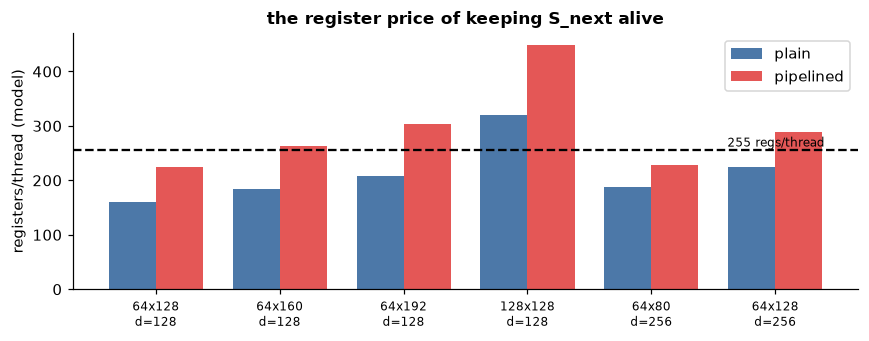

<sub>**Figure.** Red bars are what pipelining costs. In our register model the 64x160 and 64x192 tiles (d=128) and 64x128 (d=256) fit when plain but cross the 255-register line once pipelined, so the pipelined kernel must shrink the tile or spill; a 128-row tile with fp32 accumulators does not fit even unpipelined, which is why per-warpgroup tiles are 64 rows in this model. Notice that this is a cost our timeline simulator ignores: it assumes any schedule is free to exist, whereas a real kernel picks the tile that fits.</sub>

True

In [7]:
def regs_per_thread(Br, Bc, d, pipelined, threads=128):
    words = Br * d + Br * Bc + (Br * Bc if pipelined else 0) + Br * Bc // 2      # O acc + S (+S_next) + P in fp16
    return words / threads
print(f"{'Br':>4} {'Bc':>4} {'d':>4} | regs/thread plain | pipelined | fits in 255?")
tab = []
for Br, Bc, d in [(64, 128, 128), (64, 160, 128), (64, 192, 128), (128, 128, 128), (64, 80, 256), (64, 128, 256)]:
    r0, r1 = regs_per_thread(Br, Bc, d, False), regs_per_thread(Br, Bc, d, True); tab.append((Br, Bc, d, r0, r1))
    print(f"{Br:>4} {Bc:>4} {d:>4} | {r0:>17.0f} | {r1:>9.0f} | plain {'yes' if r0 <= 255 else 'NO '} / pipelined {'yes' if r1 <= 255 else 'NO'}")
fig, ax = plt.subplots(figsize=(8, 3.2)); x = np.arange(len(tab)); w = .38
ax.bar(x - w/2, [t[3] for t in tab], w, color=COL["q"], label="plain"); ax.bar(x + w/2, [t[4] for t in tab], w, color=COL["o"], label="pipelined"); ax.axhline(255, color="k", ls="--"); ax.text(len(tab) - .6, 262, "255 regs/thread", fontsize=8, ha="right")
ax.set_xticks(x); ax.set_xticklabels([f"{t[0]}x{t[1]}\nd={t[2]}" for t in tab], fontsize=8); ax.set_ylabel("registers/thread (model)"); ax.legend(); ax.set_title("the register price of keeping S_next alive")
plt.tight_layout(); plt.show()
caption("Red bars are what pipelining costs. In our register model the 64x160 and 64x192 tiles (d=128) and 64x128 (d=256) fit when plain but cross the 255-register line once pipelined, so the pipelined kernel must shrink the tile or spill; a 128-row tile with fp32 accumulators does not fit even unpipelined, which is why per-warpgroup tiles are 64 rows in this model. Notice that this is a cost our timeline simulator ignores: it assumes any schedule is free to exist, whereas a real kernel picks the tile that fits.")
check("pipelining always needs more registers than plain", all(t[4] > t[3] for t in tab))
check("some natural tile shapes stop fitting once pipelined", any(t[3] <= 255 < t[4] for t in tab))

We can now add the pipelined order to the simulator (`pipelined=True`) and compare all five schedules side by side. The simulator treats `g0` as asynchronous, so issuing it before `sm` lets the tensor core work during the softmax.

schedule                  | d=64: t/iter  TC util | d=128: t/iter  TC util | d=256: t/iter  TC util 
A serial                  |         4.481     45% |         3.491     57% |         2.995     67% 
B +TMA                    |         3.997     50% |         3.006     67% |         2.511     80% 
C 2WG                     |         2.038     98% |         2.255     89% |         2.132     94% 
D 2WG ping-pong           |         2.989     67% |         2.008    100% |         2.008    100% 
E ping-pong + pipelined   |         2.020     99% |         2.008    100% |         2.008    100% 


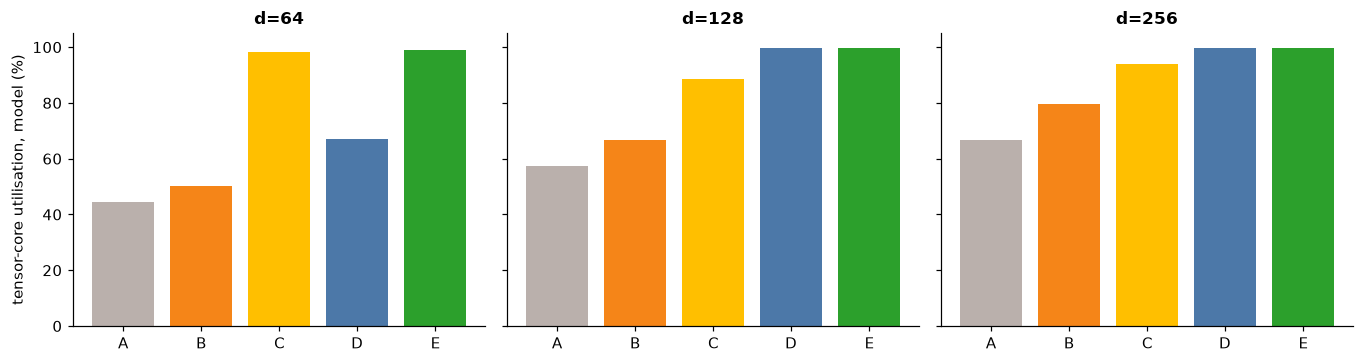

<sub>**Figure.** Tensor-core utilisation in our model for the five schedules. At d=128 each added mechanism raises the bar (57, 67, 89, 100, 100%). At d=64 the picture is not monotone in the individual steps: two uncoordinated warpgroups reach 98%, strict ping-pong drops to 67%, and adding the in-warpgroup pipelining brings it back to 99%. Notice that at d=256 two warpgroups alone already reach 94%, so the softmax is small enough that most of the gain comes from the first overlap step.</sub>

True

In [8]:
names = ["A serial", "B +TMA", "C 2WG", "D 2WG ping-pong", "E ping-pong + pipelined"]
cfgs = [dict(wgs=1, sync_tc=True, async_load=False), dict(wgs=1, sync_tc=True, async_load=True), dict(wgs=2, sync_tc=False),
        dict(wgs=2, sync_tc=False, tc_order="rr"), dict(wgs=2, sync_tc=False, tc_order="rr", pipelined=True)]
table = {}
for d in (64, 128, 256):
    for nm, kw in zip(names, cfgs):
        mk, u, ev = simulate(d, iters=32, **kw); table[(d, nm)] = (mk / (32 * kw["wgs"]), u, ev)
print(f"{'schedule':<26}" + "".join(f"| d={d}: t/iter  TC util " for d in (64, 128, 256)))
for nm in names: print(f"{nm:<26}" + "".join(f"| {table[(d, nm)][0]:>13.3f} {table[(d, nm)][1]*100:>6.0f}% " for d in (64, 128, 256)))
fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.4), sharey=True)
for ax, d in zip(axs, (64, 128, 256)):
    ax.bar(range(5), [table[(d, n)][1] * 100 for n in names], color=[COL["hbm"], COL["k"], COL["mid"], COL["q"], COL["good"]]); ax.set_xticks(range(5)); ax.set_xticklabels(["A", "B", "C", "D", "E"]); ax.set_title(f"d={d}"); ax.set_ylim(0, 105)
axs[0].set_ylabel("tensor-core utilisation, model (%)"); plt.tight_layout(); plt.show()
caption("Tensor-core utilisation in our model for the five schedules. At d=128 each added mechanism raises the bar (57, 67, 89, 100, 100%). At d=64 the picture is not monotone in the individual steps: two uncoordinated warpgroups reach 98%, strict ping-pong drops to 67%, and adding the in-warpgroup pipelining brings it back to 99%. Notice that at d=256 two warpgroups alone already reach 94%, so the softmax is small enough that most of the gain comes from the first overlap step.")
u = {n: table[(128, n)][1] for n in names}
HEAD["util128"] = u
check("utilisation is monotone non-decreasing A->E at d=128 (model)", all(u[names[i]] <= u[names[i+1]] + 1e-9 for i in range(4)))
check("fully overlapped schedule reaches >90% TC utilisation at d=128 (model)", u[names[4]] > 0.9)
check("strict ping-pong is worse than uncoordinated at d=64 (model finding)", table[(64, names[3])][1] < table[(64, names[2])][1])

In our model the fully serial schedule gets 57% tensor-core utilisation at $d=128$ (67% once the copies are hidden) and the final schedule gets close to full. That ceiling is not what the paper reports (about 75% of peak) because real kernels also pay for barriers, register spilling, causal imbalance and the pieces our model omits; we treat the model as showing the *direction and rough share* of each mechanism, not a prediction.

## 5. FP8 attention: error, block quantisation, incoherent processing

**A tiny example.** FP8 e4m3 has 1 sign, 4 exponent and 3 mantissa bits, a maximum of 448, and a relative rounding error of up to $2^{-4}=6.25\%$. Quantising a number to e4m3 therefore loses about one digit.

In [9]:
x = torch.tensor([0.3, 1.0, 3.7, 17.0, 100.0, 300.0])
q8 = x.to(torch.float8_e4m3fn).to(torch.float32); print("x     :", x.tolist()); print("e4m3  :", q8.tolist()); print("rel.err:", ((q8 - x).abs() / x).tolist())
fin = torch.finfo(torch.float8_e4m3fn); print(f"e4m3: max={fin.max}, smallest normal={fin.tiny}, eps={fin.eps}")
check("e4m3 relative error is at most 2^-4 for in-range normals", ((q8 - x).abs() / x).max() <= 2**-4 + 1e-6)

x     : [0.30000001192092896, 1.0, 3.700000047683716, 17.0, 100.0, 300.0]
e4m3  : [0.3125, 1.0, 3.75, 16.0, 96.0, 288.0]
rel.err: [0.041666626930236816, 0.0, 0.013513500802218914, 0.05882352963089943, 0.03999999910593033, 0.03999999910593033]
e4m3: max=448.0, smallest normal=0.015625, eps=0.125


tensor(True)

**General definition.** Quantisation with a scale $s$: $\hat x=s\cdot\mathrm{cast}_{e4m3}(x/s)$, with $s=\max|x|/448$ so the largest value uses the range. FP8 is a *floating-point* format, so rounding error is relative to each element. That has a consequence we will test rather than assume: **a single large channel does not make the small channels less precise, but it does make the dot product $q\cdot k$ inaccurate**, because the dot product is dominated by the large channel and its own 6% error then sets the error of the whole logit. LLM activations are known to have a few such outlier channels (reported widely in the quantisation literature).

**Incoherent processing** (the paper's term, from the QuIP line of work) multiplies $Q$ and $K$ by the same random orthogonal matrix $M$: $(QM)(KM)^\top=QK^\top$. Choosing $M=\tfrac1{\sqrt d}\,\mathrm{diag}(\pm1)\,H$ with $H$ a Hadamard matrix spreads each outlier across all channels, so no channel dominates, and it can be applied in $O(d\log d)$ per row with a fast Walsh-Hadamard transform. Below: $M$ is orthogonal, and spreads a one-hot vector evenly.

In [10]:
def hadamard(n):
    H = torch.ones(1, 1, dtype=torch.float64)
    while H.shape[0] < n: H = torch.cat([torch.cat([H, H], 1), torch.cat([H, -H], 1)], 0)
    return H
def incoherent_matrix(d, seed=0):
    g = torch.Generator(device=DEVICE).manual_seed(seed); s = (torch.randint(0, 2, (d,), generator=g) * 2 - 1).double()
    return (s[:, None] * hadamard(d)) / math.sqrt(d)           # diag(+-1) H / sqrt(d)
d = 64; Mq = incoherent_matrix(d)
print("M M^T = I ?", max_err(Mq @ Mq.T, torch.eye(d)))
e = torch.zeros(d, dtype=torch.float64); e[3] = 100.0; sp = e @ Mq
print(f"one-hot outlier 100 -> after rotation: max|x|={sp.abs().max():.3f}, min|x|={sp.abs().min():.3f} (all equal in magnitude: {100/math.sqrt(d):.3f})")
a, b = torch.randn(5, d, dtype=torch.float64), torch.randn(7, d, dtype=torch.float64)
check("M is orthogonal", max_err(Mq @ Mq.T, torch.eye(d)) < 1e-12)
check("(QM)(KM)^T == QK^T exactly", max_err((a @ Mq) @ (b @ Mq).T, a @ b.T) < 1e-12)
check("rotation spreads a one-hot outlier evenly across channels", (sp.abs().max() - sp.abs().min()) < 1e-9)

M M^T = I ? 0.0
one-hot outlier 100 -> after rotation: max|x|=12.500, min|x|=12.500 (all equal in magnitude: 12.500)


tensor(True)

**How it is implemented.** Below is a tile-wise FP8 flash forward. $Q$ and $K$ tiles are quantised with a scale per *block* (or per tensor, to compare); the QK matmul uses the quantised values with fp32 accumulation (a product of two e4m3 numbers is exact in fp32, so this emulates an FP8 GEMM); $\tilde P=e^{S-m}\in[0,1]$ is cast to e4m3 using a fixed scale of 448; $V$ is quantised per tensor. Everything else (the online softmax and the output accumulator) stays fp32.

**Test data.** To make the comparison meaningful we need $Q,K$ with realistic structure: two outlier channels (x20 in both $Q$ and $K$) plus per-block magnitude variation. We state this as a *synthetic* setting: the result below is about this data, not about any specific model.

In [11]:
def fq(x, scale): return (x / scale).to(torch.float8_e4m3fn).to(torch.float32) * scale
def amax_scale(x): return x.abs().max().clamp_min(1e-12) / 448.0

def fp8_flash_forward(q, k, v, Br=64, Bc=64, block_quant=True, M=None):
    """FA-2-style loop with FP8 Q/K/P/V. M: optional (d,d) orthogonal matrix applied to Q and K (incoherent processing)."""
    N, d = q.shape; sc = 1 / math.sqrt(d); q, k, v = q.float(), k.float(), v.float()
    if M is not None: q, k = q @ M.float(), k @ M.float()
    s_q_all, s_k_all, s_v = amax_scale(q), amax_scale(k), amax_scale(v); vq = fq(v, s_v)
    O = torch.zeros_like(q)
    for i in range(math.ceil(N / Br)):
        is_ = slice(i*Br, min((i+1)*Br, N)); Qi = q[is_]; sq = amax_scale(Qi) if block_quant else s_q_all; Qq = fq(Qi, sq)
        Ot = torch.zeros(len(Qi), d); li = torch.zeros(len(Qi)); mi = torch.full((len(Qi),), -float("inf"))
        for j in range(math.ceil(N / Bc)):
            js = slice(j*Bc, min((j+1)*Bc, N)); Kj = k[js]; sk = amax_scale(Kj) if block_quant else s_k_all; Kq = fq(Kj, sk)
            S = (Qq @ Kq.T) * sc                                              # fp8 x fp8 -> fp32 accumulate
            mn = torch.maximum(mi, S.max(1).values); P = torch.exp(S - mn[:, None]); a = torch.exp(mi - mn)
            li = a * li + P.sum(1); Ot = a[:, None] * Ot + fq(P, 1 / 448.0) @ vq[js]; mi = mn       # P in [0,1] -> scale 1/448
        O[is_] = Ot / li[:, None]
    return O

def make_qkv(N=512, d=64, outlier=20.0, block_spread=1.0, seed=0):
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    q, k, v = (torch.randn(N, d, generator=g, dtype=torch.float64) for _ in range(3))
    for ch in (3, 17): q[:, ch] *= outlier; k[:, ch] *= outlier
    blk = torch.exp(torch.randn(N // 64, generator=g, dtype=torch.float64) * block_spread).repeat_interleave(64)[:, None]
    return q * blk ** .5, k * blk ** .5, v
q, k, v = make_qkv(); ref, _ = ref_attention(q, k, v)
rmse = lambda o: ((o.double() - ref) ** 2).mean().sqrt().item()
Mq = incoherent_matrix(64)
res = {"fp32 (no quantisation)": rmse(fp8_flash_forward.__globals__["ref_attention"](q, k, v)[0].float()),
       "FP8 per-tensor": rmse(fp8_flash_forward(q, k, v, block_quant=False)),
       "FP8 per-block": rmse(fp8_flash_forward(q, k, v, block_quant=True)),
       "FP8 per-tensor + incoherent": rmse(fp8_flash_forward(q, k, v, block_quant=False, M=Mq)),
       "FP8 per-block + incoherent": rmse(fp8_flash_forward(q, k, v, block_quant=True, M=Mq))}
for kx, vx in res.items(): print(f"{kx:<30} RMSE vs float64 = {vx:.3e}")
HEAD["fp8"] = res
base = res["FP8 per-tensor"]; best = res["FP8 per-block + incoherent"]
print(f"\nper-tensor FP8 / (per-block + incoherent) error ratio = {base/best:.2f}x;  per-tensor / (per-tensor + incoherent) = {base/res['FP8 per-tensor + incoherent']:.2f}x   (paper reports 2.6x on its own data; this is a toy)")
S_ = (q.float() @ k.float().T) / 8; print(f"context: logit std = {S_.std():.1f}, attention-output RMS = {ref.pow(2).mean().sqrt():.3f}  -> the toy is deliberately severe (large logits make 6% rounding matter)")
check("FP8 error is larger than fp32-rounding error", res["FP8 per-tensor"] > 10 * res["fp32 (no quantisation)"])
check("incoherent processing reduces FP8 error in this setting", res["FP8 per-block + incoherent"] < res["FP8 per-block"])

fp32 (no quantisation)         RMSE vs float64 = 2.393e-08
FP8 per-tensor                 RMSE vs float64 = 3.372e-01
FP8 per-block                  RMSE vs float64 = 3.126e-01
FP8 per-tensor + incoherent    RMSE vs float64 = 9.678e-02
FP8 per-block + incoherent     RMSE vs float64 = 1.240e-01

per-tensor FP8 / (per-block + incoherent) error ratio = 2.72x;  per-tensor / (per-tensor + incoherent) = 3.48x   (paper reports 2.6x on its own data; this is a toy)
context: logit std = 50.4, attention-output RMS = 0.943  -> the toy is deliberately severe (large logits make 6% rounding matter)


True

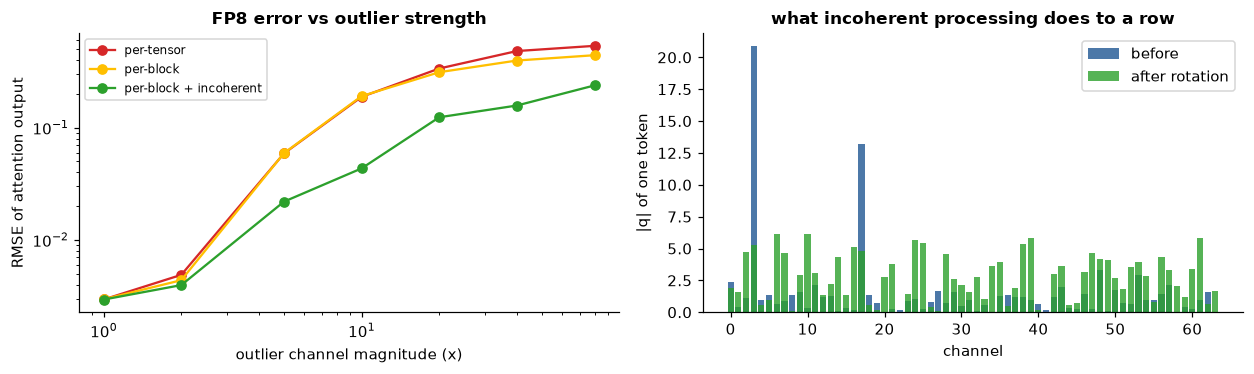

<sub>**Figure.** Left: error grows with outlier size for plain FP8, and the rotated version grows much more slowly; with no outliers (x1) all three variants are indistinguishable (about 2.9e-3). Right: one token before (blue) and after (green) rotation: the two outlier channels are spread into a flat profile. Notice that block quantisation barely separates the first two curves here, which we discuss next.</sub>

outlier x1  : per-tensor 2.941e-03  per-block 2.955e-03  per-block+incoherent 2.937e-03
outlier x2  : per-tensor 4.877e-03  per-block 4.371e-03  per-block+incoherent 3.953e-03
outlier x5  : per-tensor 5.894e-02  per-block 5.926e-02  per-block+incoherent 2.191e-02
outlier x10 : per-tensor 1.884e-01  per-block 1.913e-01  per-block+incoherent 4.338e-02
outlier x20 : per-tensor 3.372e-01  per-block 3.126e-01  per-block+incoherent 1.240e-01
outlier x40 : per-tensor 4.826e-01  per-block 3.972e-01  per-block+incoherent 1.577e-01
outlier x80 : per-tensor 5.369e-01  per-block 4.431e-01  per-block+incoherent 2.384e-01


In [12]:
# sweep outlier strength: error vs how large the outlier channels are
outs = [1, 2, 5, 10, 20, 40, 80]; E = {k_: [] for k_ in ("per-tensor", "per-block", "per-block + incoherent")}
for o in outs:
    q, k, v = make_qkv(outlier=o); ref, _ = ref_attention(q, k, v); rm = lambda x: ((x.double() - ref) ** 2).mean().sqrt().item()
    E["per-tensor"].append(rm(fp8_flash_forward(q, k, v, block_quant=False))); E["per-block"].append(rm(fp8_flash_forward(q, k, v, block_quant=True)))
    E["per-block + incoherent"].append(rm(fp8_flash_forward(q, k, v, block_quant=True, M=Mq)))
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.5))
for (k_, v_), c in zip(E.items(), (COL["bad"], COL["mid"], COL["good"])): axs[0].plot(outs, v_, "o-", color=c, label=k_)
axs[0].set_xscale("log"); axs[0].set_yscale("log"); axs[0].set_xlabel("outlier channel magnitude (x)"); axs[0].set_ylabel("RMSE of attention output"); axs[0].legend(fontsize=8); axs[0].set_title("FP8 error vs outlier strength")
q, k, v = make_qkv(outlier=20); sample = (q[:, :] ).double(); axs[1].bar(range(64), q[0].abs().cpu().numpy(), color=COL["q"], label="before"); axs[1].bar(range(64), (q[0] @ Mq).abs().cpu().numpy(), color=COL["good"], alpha=.8, label="after rotation")
axs[1].set_xlabel("channel"); axs[1].set_ylabel("|q| of one token"); axs[1].legend(); axs[1].set_title("what incoherent processing does to a row")
plt.tight_layout(); plt.show()
caption("Left: error grows with outlier size for plain FP8, and the rotated version grows much more slowly; with no outliers (x1) all three variants are indistinguishable (about 2.9e-3). Right: one token before (blue) and after (green) rotation: the two outlier channels are spread into a flat profile. Notice that block quantisation barely separates the first two curves here, which we discuss next.")
for o_, a_, b_, c_ in zip(outs, E['per-tensor'], E['per-block'], E['per-block + incoherent']): print(f'outlier x{o_:<3}: per-tensor {a_:.3e}  per-block {b_:.3e}  per-block+incoherent {c_:.3e}')
check("with strong outliers (x40) incoherent processing wins by >2x", E["per-block"][5] / E["per-block + incoherent"][5] > 2, f"{E['per-block'][5]/E['per-block + incoherent'][5]:.1f}x")
HEAD["sweep"] = (E["per-tensor"][4], E["per-block"][4], E["per-block + incoherent"][4])

We found in this toy that incoherent processing carries almost all of the gain (3.5x lower error with per-tensor scales; 2.7x with per-block scales), and per-block scaling adds little over per-tensor scaling, even making the rotated variant slightly worse at x20 (0.124 vs 0.097). That is consistent with FP8 being a floating-point format: relative error does not depend on scale until values approach the underflow limit (smallest normal 0.0156 in e4m3 units), so a scale per block matters only when blocks differ by orders of magnitude (our `block_spread=1.0` gives roughly 3x variation). We did not test the regime where block scaling would matter more. Per-block scaling is cheap (one scalar per tile) so we keep it, but the claim we can support is narrower than the paper's.

## 6. What did not help, and what it costs

We list the pieces that failed to deliver or carry a cost, each from a measurement above.

| idea | what we found | cost / limit |
|---|---|---|
| Async TMA copies alone (B) | helps only up to the load share of an iteration; tensor-core gaps remain | needs shared-memory ring buffer and a producer warp |
| Two warpgroups without barriers (C) | already captures much of the overlap in our simulator | uncoordinated order can collide; FA-3 adds barriers (D) |
| Ping-pong (D) | gain depends on d: biggest when softmax ~ GEMM time | two tiles' worth of registers and SMEM resident |
| Pipelining inside a warpgroup (E) | exact (verified), raises TC utilisation in model | second S tile: some tile shapes exceed 255 registers/thread |
| Per-tensor FP8 | error grows with outlier strength | none (baseline) |
| Per-block FP8 scales | little gain in our toy | one scalar per tile |
| Incoherent processing | large gain with outliers, none without | $O(d\log d)$ per row, extra kernel work |
| Layout (V transposed for FP8 WGMMA, P permuted) | reported in the paper, not implemented here | extra data movement |

In [13]:
u = HEAD["util128"]; r = HEAD["fp8"]
display(Markdown(f"""
| quantity (d=128 unless noted) | value | how obtained |
|---|---|---|
| exp time / matmul time | {rows[1][2]/rows[1][1]:.2f} | arithmetic from *reported* H100 rates |
| TC utilisation: serial / +TMA / +2WG / ping-pong / +pipelined | {u[names[0]]*100:.0f}% / {u[names[1]]*100:.0f}% / {u[names[2]]*100:.0f}% / {u[names[3]]*100:.0f}% / {u[names[4]]*100:.0f}% | our simulator (model) |
| FP8 RMSE per-tensor vs per-block+incoherent (d=64, x20 outliers) | {r['FP8 per-tensor']:.2e} vs {r['FP8 per-block + incoherent']:.2e} ({r['FP8 per-tensor']/r['FP8 per-block + incoherent']:.1f}x) | measured, synthetic data |
| pipelined loop exact | max error {max(errs):.1e} | measured (float64) |
| FP16 speedup over FA-2 | 1.5-2.0x | *reported*, not measured |
| FP8 throughput | ~1.2 PFLOP/s | *reported*, not measured |
"""))


| quantity (d=128 unless noted) | value | how obtained |
|---|---|---|
| exp time / matmul time | 0.50 | arithmetic from *reported* H100 rates |
| TC utilisation: serial / +TMA / +2WG / ping-pong / +pipelined | 57% / 67% / 89% / 100% / 100% | our simulator (model) |
| FP8 RMSE per-tensor vs per-block+incoherent (d=64, x20 outliers) | 3.37e-01 vs 1.24e-01 (2.7x) | measured, synthetic data |
| pipelined loop exact | max error 8.9e-16 | measured (float64) |
| FP16 speedup over FA-2 | 1.5-2.0x | *reported*, not measured |
| FP8 throughput | ~1.2 PFLOP/s | *reported*, not measured |


## 7. Closing thoughts

FlashAttention-3 does not change the mathematics of attention; every transformation in this notebook is either a reordering (pipelining, ping-pong) or a numerical-format change (FP8 with rotation). What it changes is who waits for whom: the notebook's model shows the tensor core idling for roughly a third of a serial iteration at $d=128$, and each overlap mechanism reclaims part of it.

**What is open here.** We did not run on Hopper; our simulator ignores register spills, barrier overhead, causal imbalance and L2 effects, so its utilisation numbers are an upper-bound sketch, not a prediction. The FP8 result is on synthetic outlier data and says little about real model activations. We did not implement the FP8 data-layout work (transposed V, permuted P). On the paper's own reported numbers there is also a gap between 75% FP16 utilisation and peak that we do not explain.

**Next.** Notebooks 1-3 optimise training-style attention where $N_q=N_k$. Notebook 4 turns to decoding, where one query meets a long KV cache and the sequence dimension itself must be split.

Checks run in this notebook:

In [14]:
report()

PASS exp throughput is a first-order cost at d=128 (exp/matmul > 0.4)
PASS simulator reproduces the serial per-iteration cost
PASS async loads never slow the model down
PASS two warpgroups beat one in the model at d=128
PASS ping-pong is at least as good as uncoordinated at d=128
PASS pipelined loop is exact: N=64 d=16 Br=16 Bc=16 causal=False   [err=8.9e-16]
PASS pipelined loop is exact: N=130 d=32 Br=32 Bc=64 causal=False   [err=8.9e-16]
PASS pipelined loop is exact: N=257 d=64 Br=64 Bc=64 causal=True   [err=8.9e-16]
PASS pipelined loop is exact: N=100 d=16 Br=25 Bc=30 causal=True   [err=8.9e-16]
PASS pipelining always needs more registers than plain
PASS some natural tile shapes stop fitting once pipelined
PASS utilisation is monotone non-decreasing A->E at d=128 (model)
PASS fully overlapped schedule reaches >90% TC utilisation at d=128 (model)
PASS strict ping-pong is worse than uncoordinated at d=64 (model finding)
PASS e4m3 relative error is at most 2^-4 for in-range normals
PAS